# Задание 5. Исследовательский анализ SMS (EDA)

Анализ выполняется на всём очищенном наборе до обучения; параметры моделей здесь не подбираются.

In [1]:
# Настройка путей. Работает локально и в Google Colab.
import sys
import zipfile
from pathlib import Path

if "google.colab" in sys.modules and not Path("ml").exists():
    # В Colab загрузите архив проекта sms_guard.zip (см. README).
    from google.colab import files
    uploaded = files.upload()
    zipfile.ZipFile(next(iter(uploaded))).extractall(".")

ROOT = Path.cwd() if (Path.cwd() / "ml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print("Корень проекта:", ROOT.name)

Корень проекта: AIproject


In [2]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

df = pd.read_csv(ROOT / "data" / "processed" / "sms_clean.csv", encoding="utf-8")
df["class_name"] = df["label"].map({0: "Безопасные (ham)", 1: "Мошеннические (spam)"})
COLORS = {0: "#5b8def", 1: "#c62f2f"}
print(df.shape)
df.head(3)

(5135, 5)


,id,text_raw,text_clean,label,class_name
0,1,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",0,Безопасные (ham)
1,2,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,0,Безопасные (ham)
2,3,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in <num> a wkly comp to win fa cup ...,1,Мошеннические (spam)


## 1. Распределение классов

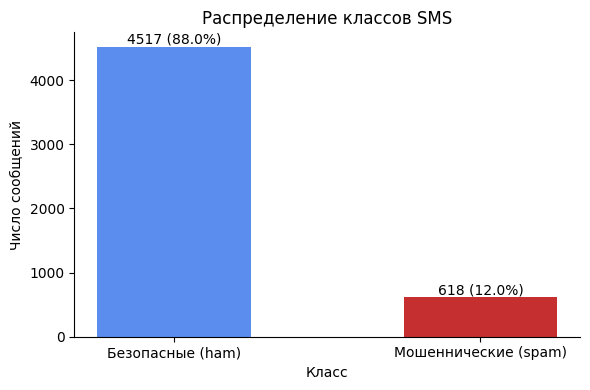

In [3]:
counts = df["label"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Безопасные (ham)", "Мошеннические (spam)"], counts, color=[COLORS[0], COLORS[1]], width=0.5)
for bar, value in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value} ({value / len(df):.1%})", ha="center", va="bottom")
ax.set_title("Распределение классов SMS")
ax.set_xlabel("Класс")
ax.set_ylabel("Число сообщений")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_01_classes.png", dpi=130)
plt.show()

## 2. Длина сообщений по классам

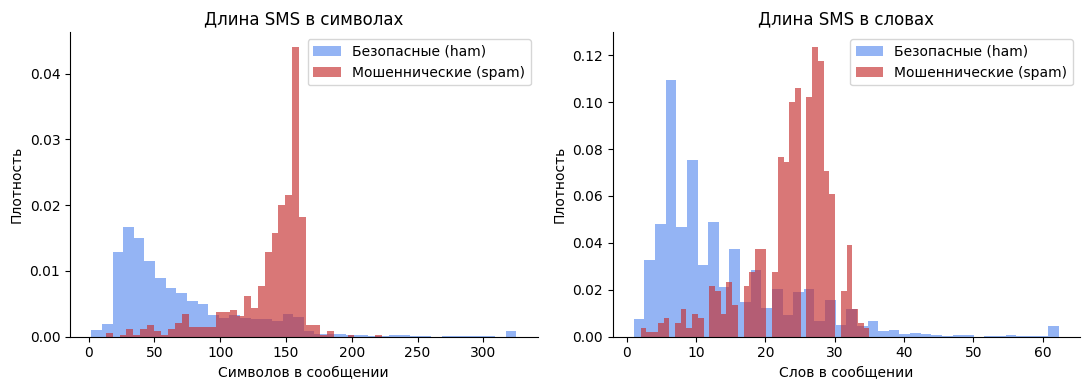

chars        words       
                       mean median  mean median
class_name                                     
Безопасные (ham)       70.9   53.0  14.2   11.0
Мошеннические (spam)  137.5  148.0  23.7   25.0

In [4]:
df["chars"] = df["text_raw"].str.len()
df["words"] = df["text_raw"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, title, xlabel in [
    (axes[0], "chars", "Длина SMS в символах", "Символов в сообщении"),
    (axes[1], "words", "Длина SMS в словах", "Слов в сообщении"),
]:
    limit = df[column].quantile(0.995)
    for label, name in [(0, "Безопасные (ham)"), (1, "Мошеннические (spam)")]:
        values = df.loc[df["label"] == label, column].clip(upper=limit)
        ax.hist(values, bins=40, density=True, alpha=0.65, color=COLORS[label], label=name)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Плотность")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_02_length.png", dpi=130)
plt.show()
df.groupby("class_name")[["chars", "words"]].agg(["mean", "median"]).round(1)

## 3. Топ-20 слов и биграмм для каждого класса (без стоп-слов)

In [5]:
TOKEN_RE = re.compile(r"[a-zа-яё']{2,}")

def tokens(text):
    return [t for t in TOKEN_RE.findall(text) if t not in ENGLISH_STOP_WORDS]

def top_ngrams(texts, n, k=20):
    counter = Counter()
    for text in texts:
        words = tokens(text)
        counter.update(" ".join(words[i:i + n]) for i in range(len(words) - n + 1))
    return counter.most_common(k)

tables = {}
for label, name in [(0, "ham"), (1, "spam")]:
    texts = df.loc[df["label"] == label, "text_clean"]
    tables[f"{name}: слово"] = [w for w, _ in top_ngrams(texts, 1)]
    tables[f"{name}: кол-во"] = [c for _, c in top_ngrams(texts, 1)]
    tables[f"{name}: биграмма"] = [w for w, _ in top_ngrams(texts, 2)]
    tables[f"{name}: кол-во "] = [c for _, c in top_ngrams(texts, 2)]
pd.DataFrame(tables)

,ham: слово,ham: кол-во,ham: биграмма,ham: кол-во,spam: слово,spam: кол-во,spam: биграмма,spam: кол-во
0,num,1083,lt gt,254,num,1714,num num,278
1,i'm,370,num num,76,money,411,phone num,54
2,gt,288,let know,40,phone,386,num money,51
3,lt,287,wan num,31,free,189,box num,47
4,just,282,good morning,24,txt,133,num free,39
5,ok,254,i'm going,22,url,119,num ppm,38
6,got,228,new year,21,stop,116,money prize,36
7,know,226,num pm,20,ur,115,money cash,35
8,like,224,just got,20,text,107,money min,31
9,good,217,num th,19,mobile,104,pobox num,30


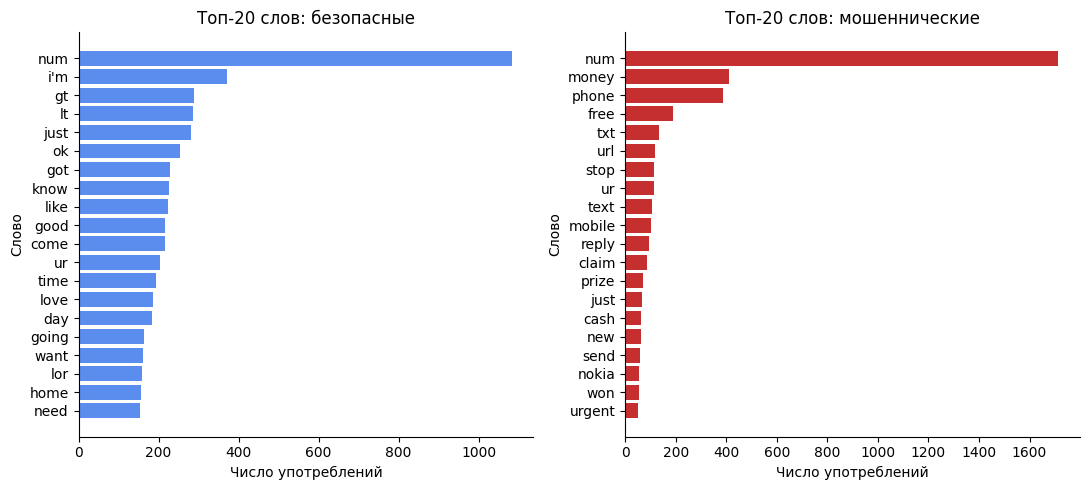

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, label, title in [(axes[0], 0, "Топ-20 слов: безопасные"), (axes[1], 1, "Топ-20 слов: мошеннические")]:
    top = top_ngrams(df.loc[df["label"] == label, "text_clean"], 1)[::-1]
    ax.barh([w for w, _ in top], [c for _, c in top], color=COLORS[label])
    ax.set_title(title)
    ax.set_xlabel("Число употреблений")
    ax.set_ylabel("Слово")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_03_top_words.png", dpi=130)
plt.show()

## 4. Доля сообщений с токенами и восклицательным знаком

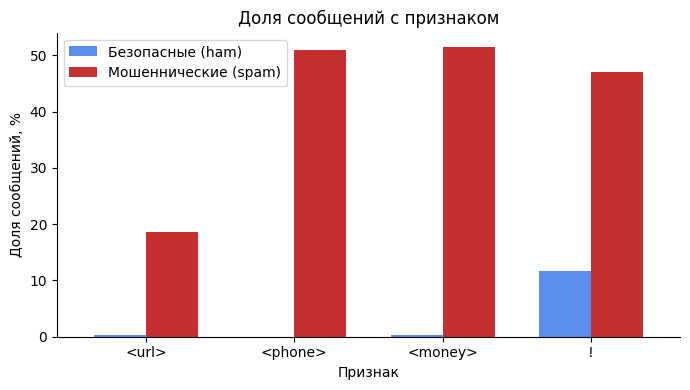

,Безопасные (ham),Мошеннические (spam)
<url>,0.2,18.6
<phone>,0.0,51.0
<money>,0.3,51.5
!,11.7,47.1


In [7]:
marks = {"<url>": "<url>", "<phone>": "<phone>", "<money>": "<money>", "!": "!"}
shares = pd.DataFrame({
    name: df.groupby("label")["text_clean"].apply(lambda s: s.str.contains(mark, regex=False).mean())
    for name, mark in marks.items()
}).T
shares.columns = ["Безопасные (ham)", "Мошеннические (spam)"]

ax = (shares * 100).plot.bar(figsize=(7, 4), color=[COLORS[0], COLORS[1]], rot=0, width=0.7)
ax.set_title("Доля сообщений с признаком")
ax.set_xlabel("Признак")
ax.set_ylabel("Доля сообщений, %")
ax.spines[["top", "right"]].set_visible(False)
ax.figure.tight_layout()
ax.figure.savefig(FIGURES / "eda_04_tokens.png", dpi=130)
plt.show()
(shares * 100).round(1)

## 5. Наблюдения

Числа в выводах вычисляются из данных, поэтому всегда совпадают с набором.

In [8]:
means = df.groupby("label")[["chars", "words"]].mean()
spam_share = df["label"].mean()
top_spam = [w for w, _ in top_ngrams(df.loc[df["label"] == 1, "text_clean"], 1, 5)]
print(f"1. Дисбаланс: spam всего {spam_share:.1%}. Accuracy постоянного ответа «ham» была бы {1 - spam_share:.1%}, поэтому она не подходит как главная метрика.")
print(f"2. Spam длиннее: в среднем {means.loc[1, 'chars']:.0f} символов против {means.loc[0, 'chars']:.0f} у ham.")
print(f"3. Ссылки: <url> встречается в {shares.iloc[0, 1]:.1%} spam и в {shares.iloc[0, 0]:.1%} ham.")
print(f"4. Телефоны: <phone> встречается в {shares.iloc[1, 1]:.1%} spam и в {shares.iloc[1, 0]:.1%} ham.")
print(f"5. Суммы: <money> встречается в {shares.iloc[2, 1]:.1%} spam и в {shares.iloc[2, 0]:.1%} ham.")
print(f"6. Восклицательные знаки: {shares.iloc[3, 1]:.1%} spam и {shares.iloc[3, 0]:.1%} ham.")
print(f"7. Самые частые слова spam: {', '.join(top_spam)}.")

1. Дисбаланс: spam всего 12.0%. Accuracy постоянного ответа «ham» была бы 88.0%, поэтому она не подходит как главная метрика.
2. Spam длиннее: в среднем 137 символов против 71 у ham.
3. Ссылки: <url> встречается в 18.6% spam и в 0.2% ham.
4. Телефоны: <phone> встречается в 51.0% spam и в 0.0% ham.
5. Суммы: <money> встречается в 51.5% spam и в 0.3% ham.
6. Восклицательные знаки: 47.1% spam и 11.7% ham.
7. Самые частые слова spam: num, money, phone, free, txt.


## Как учитывается дисбаланс классов

- Разбиение стратифицированное: доля spam одинакова в train, val и test.
- В Logistic Regression задан `class_weight='balanced'`.
- Качество оценивается по Precision, Recall, F1 и F2 для класса spam, а не по Accuracy.

**Ограничение набора:** spam не равен мошенничеству в строгом смысле (многие сообщения просто реклама), а все тексты английские.